# From the Mutual Fund Theorem to the Security Market Line
### Does the theory survive real data?

**FE 5108 Portfolio Theory and Investments, Group project**

*Risk Management Institute, National University of Singapore*

---

This notebook is the report and the evidence together. Every table and figure is
generated from the committed data under `data/`.

**Contents**

1. [Executive summary](#1-executive-summary)
2. [Data and methodology](#2-data-and-methodology)
3. [Stage 1: portfolio choice and estimation error](#3-stage-1-portfolio-choice-and-estimation-error)
4. [Stage 2: the CAPM and the empirical SML](#4-stage-2-the-capm-and-the-empirical-sml)
5. [Robustness: the market proxy](#5-robustness-the-market-proxy)

## 1. Executive summary

We estimate mean variance portfolios and test the CAPM on 30 US securities over
119 months, then repeat on 29 Singapore names. The theory organises risk well. It
does not build a portfolio well.

The tangency portfolio fails first: it shorts one stock by 280%, and its weights
correlate at only 0.35 across the two halves of the sample (Singapore: -0.10). The
security market line also misses: the US slope is 0.016 against a theoretical
0.019, and Singapore's intercept is -0.006. The alphas are kinder, since the US
joint test cannot reject zero (GRS p = 0.47), with 2 of 30 assets past |t| > 2.

The verdict moves with the market proxy, which lifts the US p value to 0.19. We
would hold the index, not the raw tangency portfolio.

## 2. Data and methodology

We use 30 US securities (21 large capitalisation companies, 9 sector ETFs) over
119 months, October 2016 to August 2026, and repeat the CAPM on 29 Singapore
listings. Returns are month end Yahoo prices adjusted for splits and dividends.
Tickers below 90 clean observations are dropped, and a month is kept only when
every asset has a price.

The US risk free rate is the Fama and French one month Treasury bill. Singapore
uses the MAS compounded SORA index, converted to monthly as the ratio of
consecutive month end levels. The market proxy defaults to a value weighted
composite of the same universe, replaced in Section 5 by the Fama and French
factor.

Two limitations matter. Both universes use today's members carried back ten years,
so failed firms are missing and returns are biased upward, and early Yahoo share
counts are incomplete for a few names.

**Exhibit 0. The sample.** What the two universes cover.

In [1]:
import warnings

import pandas as pd
from IPython.display import Image, display

from goldman import viz
from goldman.analysis import run_capm_analysis, run_portfolio_analysis
from goldman.config import ensure_outputs_dir, get_universe
from goldman.data import load_ff3, load_returns, load_value_weights, risk_free_series

# The Fama and French market factor is published with a one month lag, so the
# Roll check in section 5 estimates on the sample the two proxies share.
warnings.filterwarnings("ignore")

pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 120)

UNIVERSES = ["us", "sg"]
PRIMARY = "us"
OUTPUT_DIR = ensure_outputs_dir()

RETURNS = {u: load_returns(universe=u) for u in UNIVERSES}

sample = pd.DataFrame(
    {
        u: {
            "currency": get_universe(u).currency,
            "assets": RETURNS[u].shape[1],
            "months": RETURNS[u].shape[0],
            "start": f"{RETURNS[u].index[0]:%Y-%m}",
            "end": f"{RETURNS[u].index[-1]:%Y-%m}",
        }
        for u in UNIVERSES
    }
).T
sample

,currency,assets,months,start,end
us,USD,30,119,2016-10,2026-08
sg,SGD,29,119,2016-10,2026-08


**Exhibit 0. Correlation structure.** How the assets move together.

findfont: Failed to find font weight semibold for Arial, now using 700.


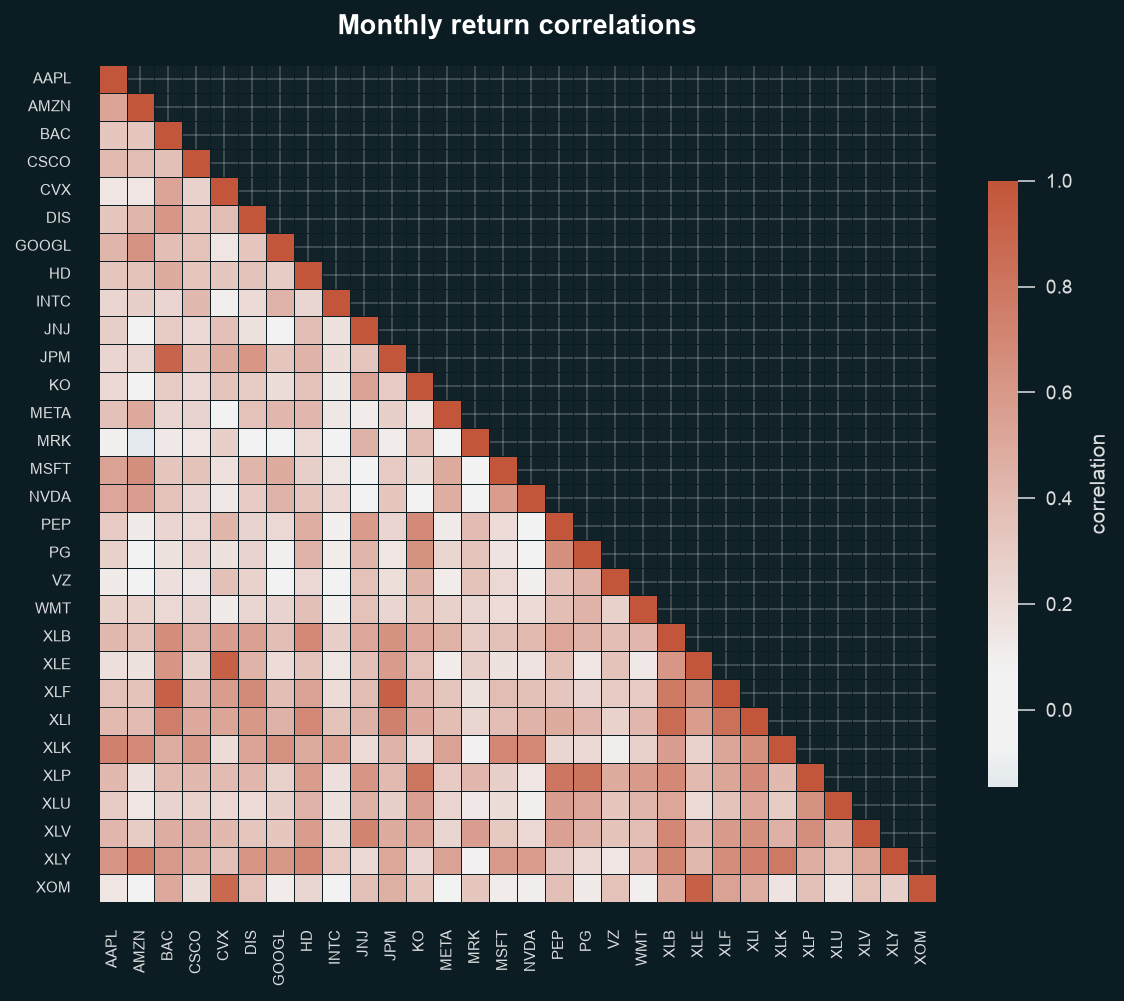

In [2]:
display(Image(filename=viz.plot_correlation(
    RETURNS[PRIMARY], OUTPUT_DIR / "correlation.png"
)))

## 3. Stage 1: portfolio choice and estimation error

The Mutual Fund Theorem says every efficient portfolio mixes the risk free asset
with the tangency portfolio. We estimate its inputs and compare with the index an
investor could buy.

### (1a) Summary statistics

In [3]:
PORTFOLIO = {
    u: run_portfolio_analysis(
        RETURNS[u],
        rf=risk_free_series(u, RETURNS[u].index),
        comparison=load_value_weights(
            universe=u, assets=RETURNS[u].columns, dates=RETURNS[u].index
        ),
        comparison_label="value weights",
        output_dir=OUTPUT_DIR / u,
    )
    for u in UNIVERSES
}
PORTFOLIO[PRIMARY].summary

,mean (ann.),vol (ann.),sharpe (ann.),min month,max month
AAPL,0.292,0.272,0.985,-0.181,0.217
AMZN,0.233,0.312,0.670,-0.238,0.273
BAC,0.202,0.286,0.626,-0.250,0.285
CSCO,0.186,0.249,0.655,-0.155,0.316
CVX,0.153,0.285,0.453,-0.224,0.273
DIS,0.068,0.306,0.146,-0.186,0.249
GOOGL,0.253,0.270,0.852,-0.179,0.338
HD,0.145,0.229,0.530,-0.151,0.189
INTC,0.224,0.532,0.377,-0.354,1.141
JNJ,0.124,0.173,0.585,-0.122,0.144


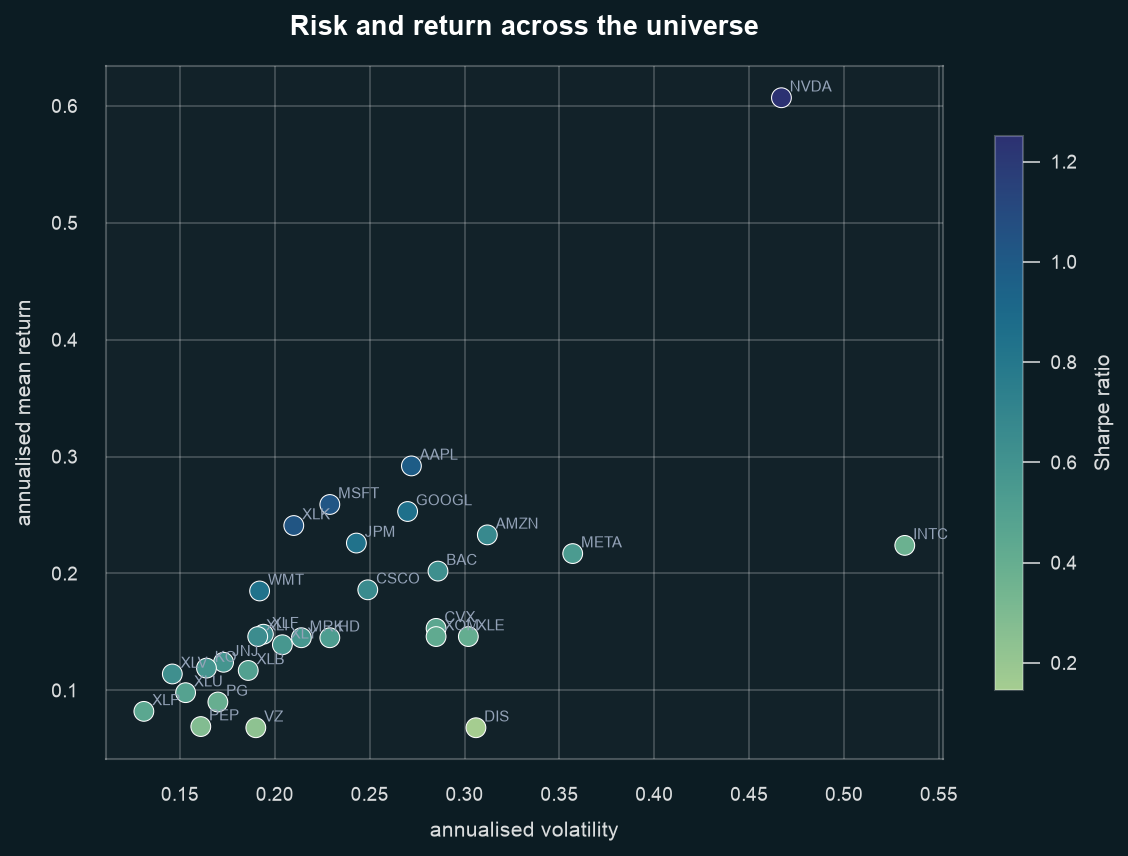

In [4]:
display(Image(filename=viz.plot_risk_return(
    PORTFOLIO[PRIMARY].summary, OUTPUT_DIR / "risk_return.png"
)))

**Takeaway.** Means range from 7% to 61% and volatilities from 13% to 53%; the
means are the least reliable inputs.

### (1b) Tangency weights versus value weights

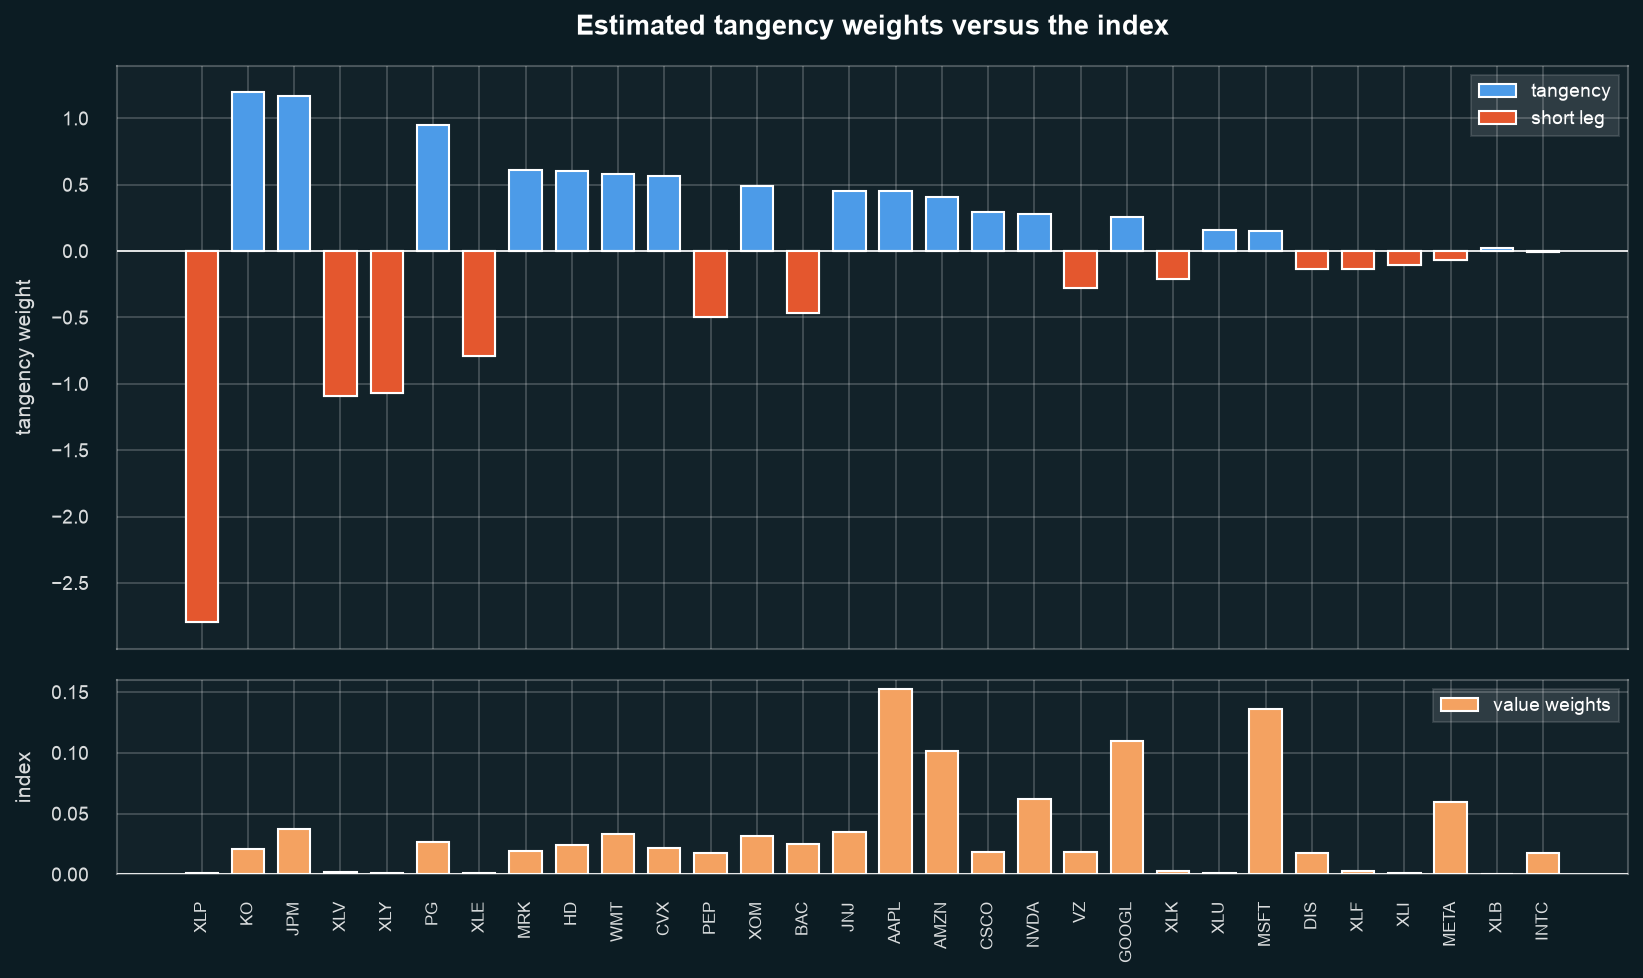

In [5]:
display(Image(filename=PORTFOLIO[PRIMARY].output_paths["weights"]))

In [6]:
w = PORTFOLIO[PRIMARY].weights
w.loc[w["tangency"].abs().sort_values(ascending=False).index].head(6).round(3)

,tangency,comparison
XLP,-2.797,0.001
KO,1.196,0.021
JPM,1.167,0.038
XLV,-1.091,0.002
XLY,-1.072,0.001
PG,0.949,0.026


**Takeaway.** Inverting a noisy covariance matrix turns estimation error into
extreme positions, such as a 280% short.

### (1c) How stable are the weights?

In [7]:
print(f"first and second half weight correlation: {PORTFOLIO[PRIMARY].weight_correlation:.2f}")
PORTFOLIO[PRIMARY].drift

first and second half weight correlation: 0.35


,first half,second half,full sample
AAPL,0.127,1.346,0.449
AMZN,-0.043,0.111,0.404
BAC,-0.110,-2.978,-0.467
CSCO,0.285,0.508,0.297
CVX,0.572,-0.071,0.564
DIS,0.223,-0.049,-0.134
GOOGL,0.172,0.691,0.254
HD,0.234,1.416,0.604
INTC,0.049,0.178,-0.008
JNJ,-0.297,1.470,0.456


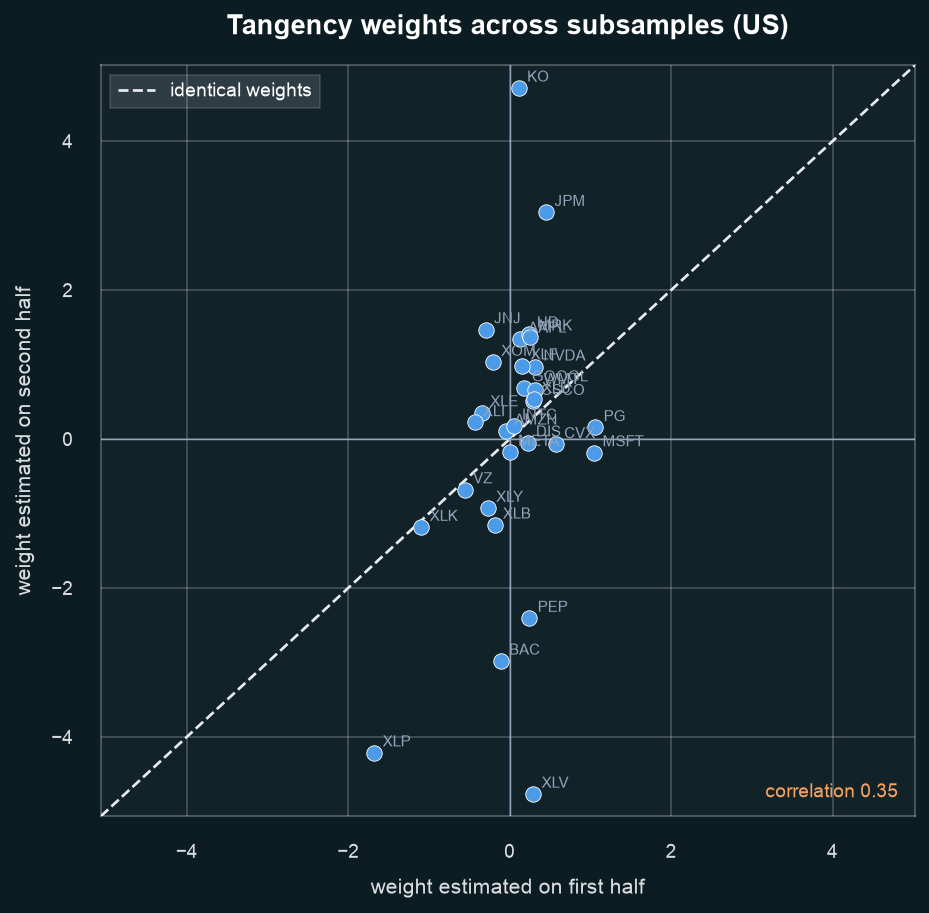

In [8]:
display(Image(filename=viz.plot_weight_drift(
    PORTFOLIO[PRIMARY].drift, OUTPUT_DIR / "weight_drift.png", label=PRIMARY
)))

**Takeaway.** The two halves correlate at only 0.35, so the extremes are noise.

### Across markets

In [9]:
pd.DataFrame(
    {
        u: {
            "assets": RETURNS[u].shape[1],
            "largest absolute tangency weight": float(PORTFOLIO[u].most_extreme_weight),
            "half sample weight correlation": float(PORTFOLIO[u].weight_correlation),
        }
        for u in UNIVERSES
    }
).T.round(3)

,assets,largest absolute tangency weight,half sample weight correlation
us,30.0,2.797,0.354
sg,29.0,0.796,-0.104


**Takeaway.** Singapore is worse, at -0.10.

### (1d) Taming the tangency portfolio

Two standard fixes reduce the extremes: a no-short constraint, and shrinkage of
both the covariance and the means.

In [10]:
from goldman.analysis.robustness import LABELS, run_robustness_analysis

FIXES = run_robustness_analysis(
    RETURNS[PRIMARY],
    rf=risk_free_series(PRIMARY, RETURNS[PRIMARY].index),
    output_dir=OUTPUT_DIR / PRIMARY,
    label=PRIMARY,
)
FIXES.diagnostics.rename(index=LABELS)[
    ["max weight", "min weight", "shorts", "gross leverage", "out of sample Sharpe"]
]

,max weight,min weight,shorts,gross leverage,out of sample Sharpe
unconstrained,1.196,-2.797,13.0,16.286,0.686
no short,0.201,0.000,0.0,1.000,0.814
shrunk,0.119,-0.055,6.0,1.351,0.857
"shrunk, no short",0.111,0.000,0.0,1.000,0.948


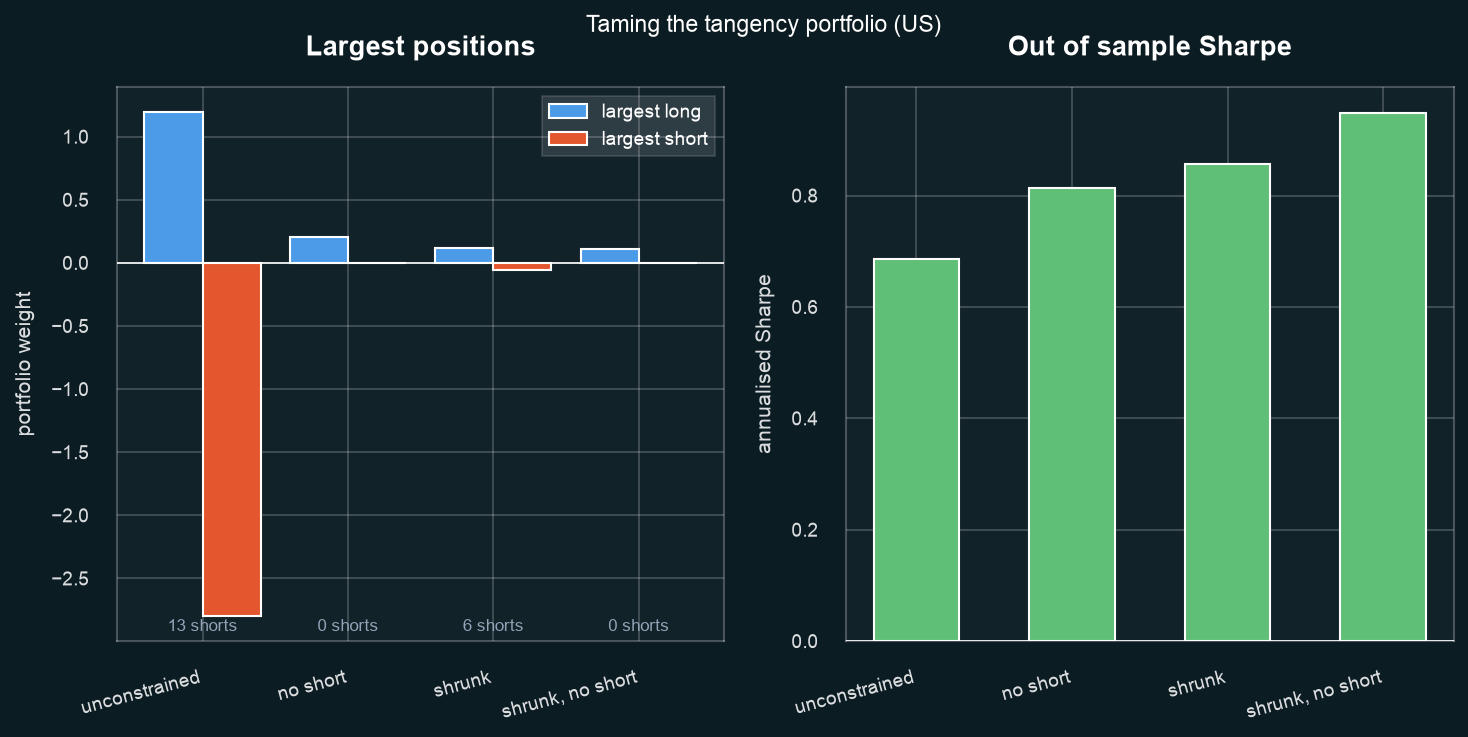

In [11]:
display(Image(filename=FIXES.output_paths["chart"]))

**Takeaway.** The largest position falls from 280% to 11% and gross leverage
from 16 to 1. Out of sample the unconstrained portfolio earns a Sharpe of 0.69
against 0.95 for the shrunk long-only version, so the fixes are not cosmetic.

## 4. Stage 2: the CAPM and the empirical SML

Stage 1 asked what an optimizer would hold. Stage 2 asks how returns line up
across assets. The CAPM predicts

$$R_{i,t} - R_{f,t} = \alpha_i + \beta_i\,(R_{M,t} - R_{f,t}) + \varepsilon_{i,t},$$

with nothing left over. We estimate it per asset and test jointly whether the
alphas are zero. With 30 assets, one or two values of |t| above 2 are expected by
chance, so the joint test carries the weight.

### (2a) Security characteristic lines

In [12]:
CAPM = {u: run_capm_analysis(RETURNS[u], universe=u, output_dir=OUTPUT_DIR) for u in UNIVERSES}
CAPM[PRIMARY].table[["beta", "alpha", "t_alpha", "p_alpha", "r_squared", "n"]].round(3)

,beta,alpha,t_alpha,p_alpha,r_squared,n
asset,,,,,,
AAPL,1.141,0.001,0.112,0.911,0.535,119
AMZN,1.417,-0.010,-1.777,0.078,0.631,119
BAC,0.953,-0.003,-0.491,0.624,0.339,119
CSCO,0.773,-0.001,-0.191,0.849,0.295,119
CVX,0.575,-0.000,-0.025,0.980,0.124,119
DIS,1.035,-0.016,-2.288,0.024,0.351,119
GOOGL,1.119,-0.002,-0.416,0.678,0.527,119
HD,0.693,-0.003,-0.560,0.577,0.279,119
INTC,1.243,-0.007,-0.507,0.613,0.167,119


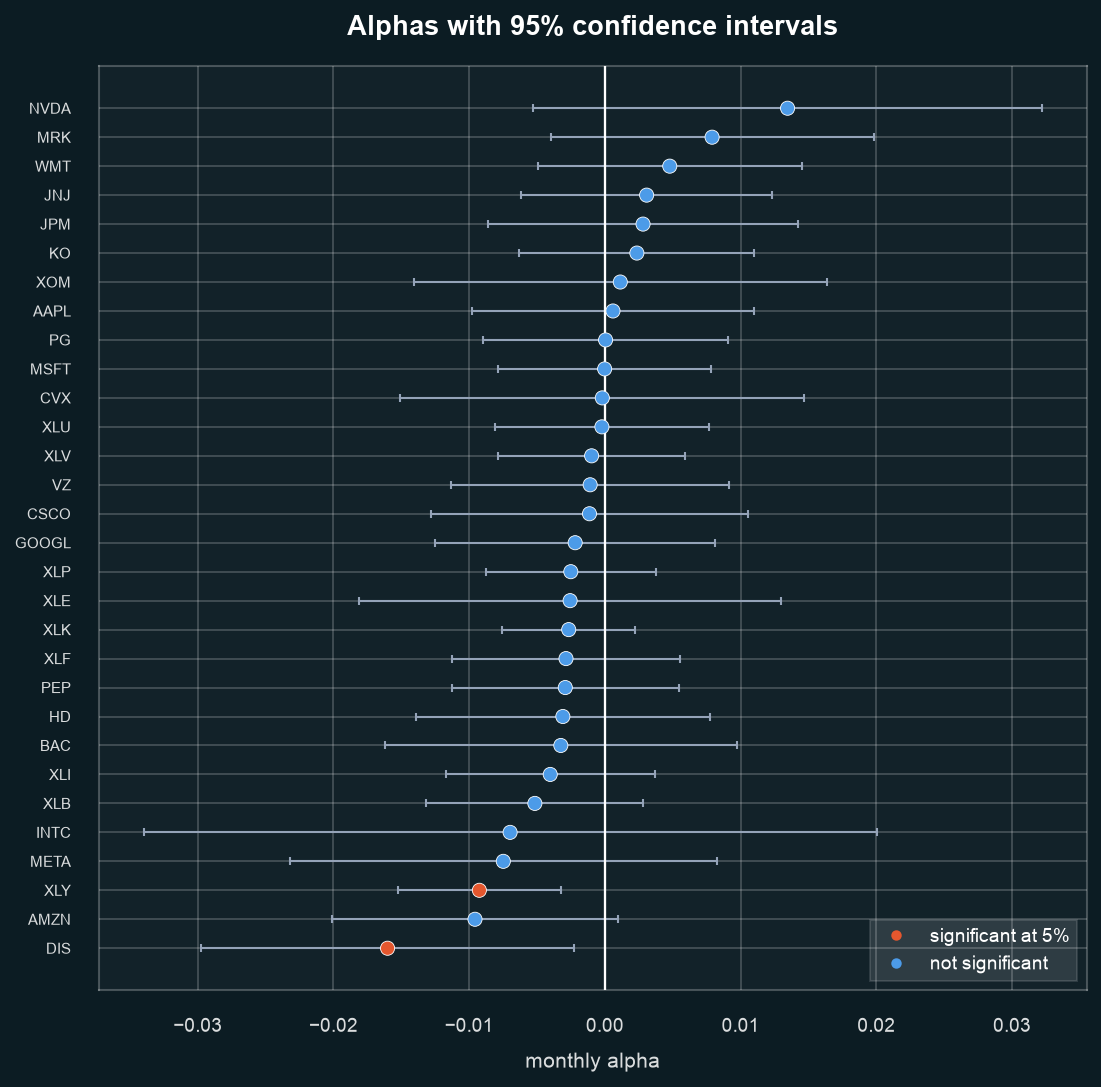

In [13]:
display(Image(filename=viz.plot_alpha_intervals(
    CAPM[PRIMARY].table, OUTPUT_DIR / "alpha_intervals.png"
)))

**Takeaway.** Betas are precise and alphas are noisy: only 2 of 30 assets reach
|t| > 2, about the chance count.

### (2b) The empirical SML

US


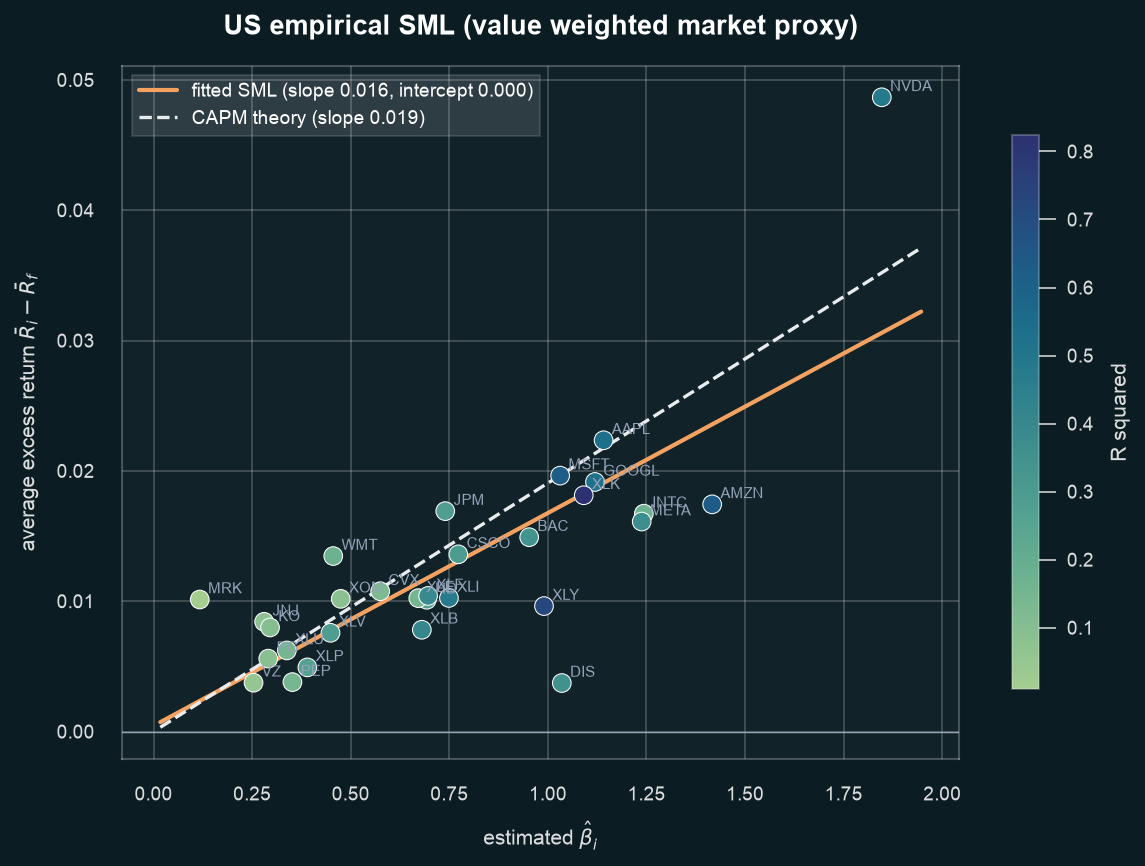

SG


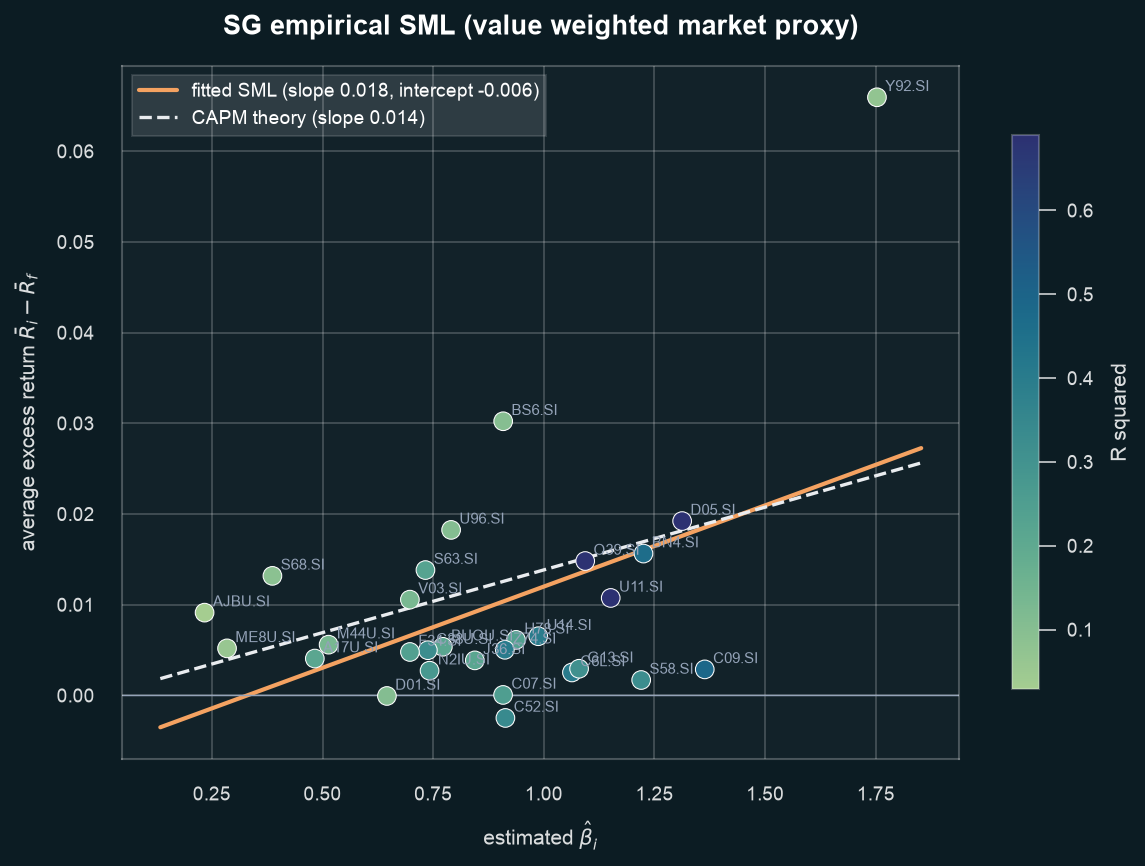

In [14]:
for u in UNIVERSES:
    print(u.upper())
    display(Image(filename=CAPM[u].output_paths["sml"]))

**Takeaway.** The US line is flatter than theory and Singapore's is steeper, so
neither matches the line through the origin.

### (2c) Are all alphas zero?

In [15]:
pd.DataFrame(
    {
        u: {
            "assets": int(c.fit.n),
            "alphas p<0.05": int((c.table["p_alpha"] < 0.05).sum()),
            "expected by chance": round(0.05 * len(c.table), 1),
            "GRS F": c.grs["f_stat"],
            "GRS p": c.grs["p_value"],
        }
        for u, c in CAPM.items()
    }
).T.round(3)

,assets,alphas p<0.05,expected by chance,GRS F,GRS p
us,30.0,2.0,1.5,1.008,0.469
sg,29.0,6.0,1.5,1.461,0.091


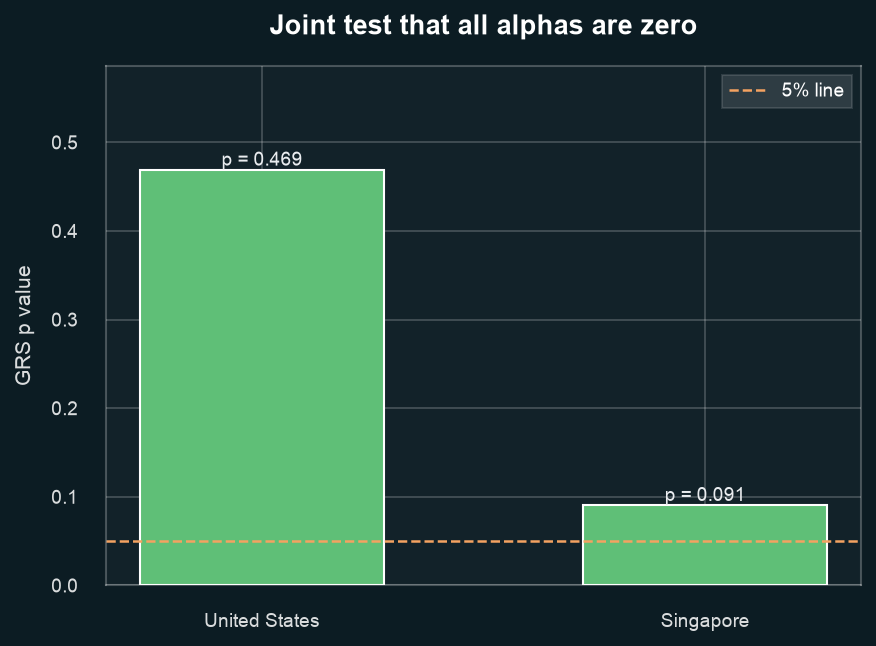

In [16]:
display(Image(filename=viz.plot_grs(CAPM, OUTPUT_DIR / "grs.png")))

**Takeaway.** The US cannot reject zero alphas (p = 0.47); Singapore is marginal (p = 0.09).

### (2d) Fitted versus theoretical SML

In [17]:
pd.DataFrame(
    {
        u: {
            "fitted slope": c.fit.slope,
            "theoretical slope": c.fit.theoretical_slope,
            "fitted intercept": c.fit.intercept,
            "cross sectional R2": c.fit.r_squared,
        }
        for u, c in CAPM.items()
    }
).T.round(4)

,fitted slope,theoretical slope,fitted intercept,cross sectional R2
us,0.0163,0.0191,0.0004,0.6100
sg,0.0179,0.0138,-0.0059,0.2166


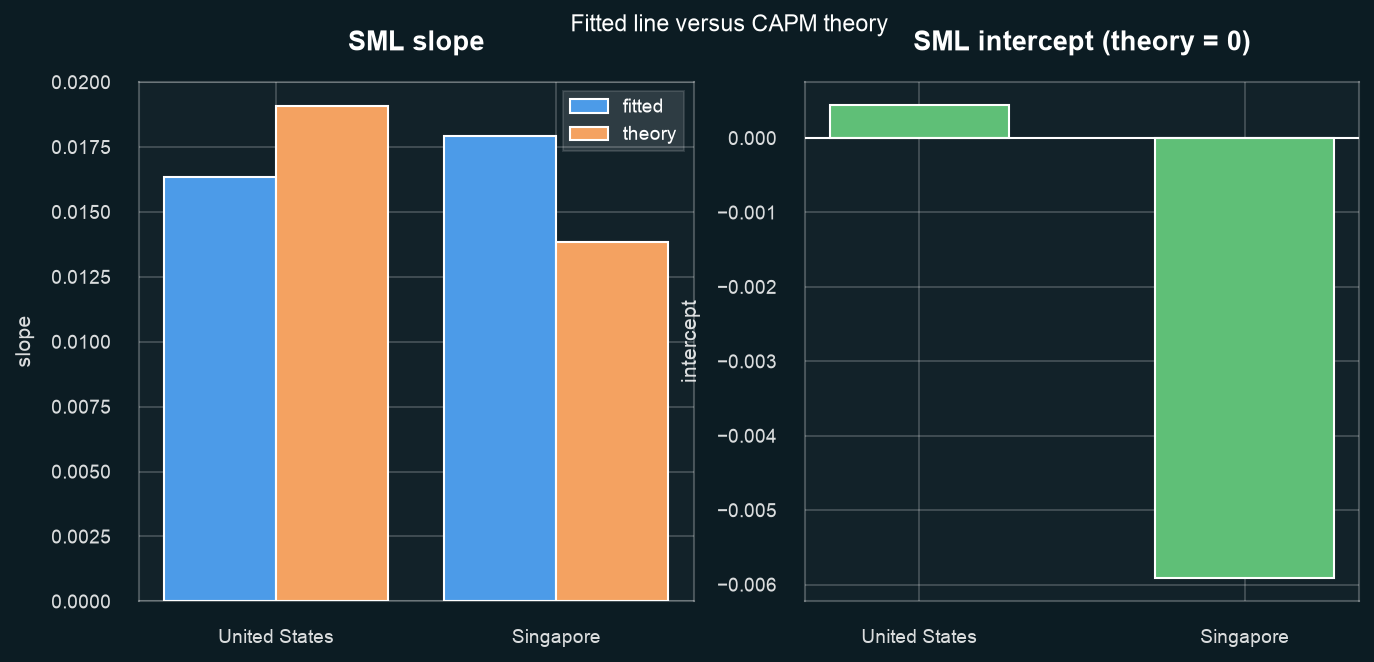

In [18]:
display(Image(filename=viz.plot_sml_fit(CAPM, OUTPUT_DIR / "sml_fit.png")))

**Takeaway.** The US slope is too flat and Singapore's intercept is negative,
against a theory of zero intercept and the average market excess return.

## 5. Robustness: the market proxy

Roll's critique: the CAPM describes the true market portfolio, which nobody
observes, so some failures blamed on the theory may belong to the proxy. We run
the US CAPM again with the Fama and French market factor.

**Exhibit 5. The same assets, two market proxies.**

In [19]:
ff3 = load_ff3()
PROXY = {
    m: run_capm_analysis(
        RETURNS[PRIMARY], universe=PRIMARY, method=m, ff3=ff3, output_dir=OUTPUT_DIR
    )
    for m in ["value_weighted", "ff_market"]
}
pd.DataFrame(
    {
        m: {
            "fitted slope": r.fit.slope,
            "theoretical slope": r.fit.theoretical_slope,
            "beta min": r.table["beta"].min(),
            "beta max": r.table["beta"].max(),
            "alphas p<0.05": int((r.table["p_alpha"] < 0.05).sum()),
            "GRS p": r.grs["p_value"],
        }
        for m, r in PROXY.items()
    }
).T.round(3)

,fitted slope,theoretical slope,beta min,beta max,alphas p<0.05,GRS p
value_weighted,0.016,0.019,0.117,1.847,2.0,0.469
ff_market,0.015,0.011,0.254,1.749,1.0,0.190


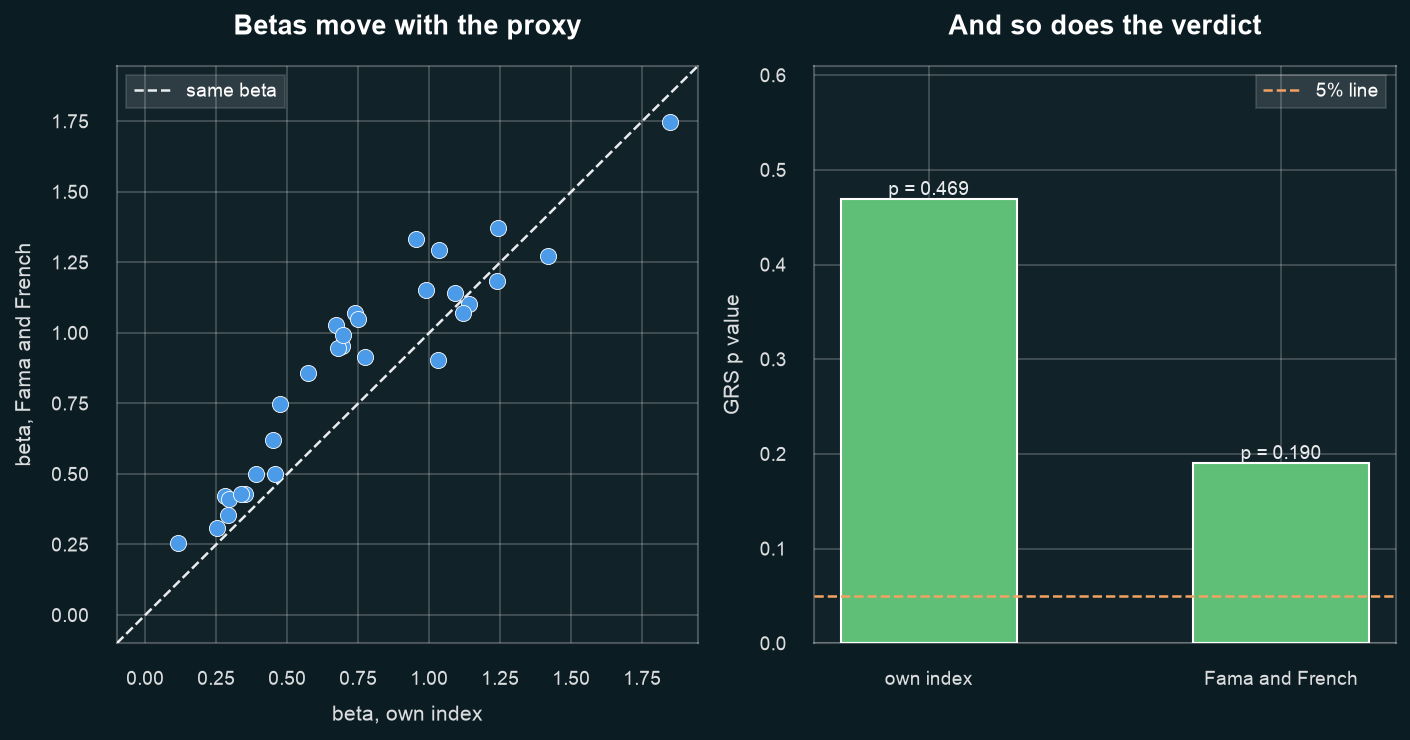

In [20]:
display(Image(filename=viz.plot_proxy_comparison(PROXY, OUTPUT_DIR / "proxy_comparison.png")))

**Takeaway.** The proxy alone halves the GRS p value, from 0.47 to 0.19.